# Cookie Cats A/B Testi - 3. İstatistiksel Testler

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/cookie_cats_clean.csv")
a = df[df["version"] == "gate_30"]
b = df[df["version"] == "gate_40"]
print(len(a), len(b))

44699 45489


## 1. Retention için iki oran z-testi

Retention 0/1 bir değişken, yani her grupta bir oran var. İki oranı karşılaştırmak için iki oran z-testi kullandım. p-değerinin yanında farkın %95 güven aralığını da hesapladım.

In [2]:
results = []
for col in ["retention_7", "retention_1"]:
    success = [b[col].sum(), a[col].sum()]
    n = [len(b), len(a)]
    z, p = proportions_ztest(success, n)
    low, high = confint_proportions_2indep(success[0], n[0], success[1], n[1], method="newcomb")
    p30, p40 = a[col].mean(), b[col].mean()
    results.append([col, p30, p40, (p40 - p30) * 100, low * 100, high * 100, (p40 / p30 - 1) * 100, z, p])

results = pd.DataFrame(results, columns=["metrik", "gate_30", "gate_40", "fark_puan",
                                         "ci_alt", "ci_ust", "goreli_fark_%", "z", "p"])
results.round(4)

,metrik,gate_30,gate_40,fark_puan,ci_alt,ci_ust,goreli_fark_%,z,p
0,retention_7,0.1902,0.1820,-0.8183,-1.3264,-0.3103,-4.3028,-3.1574,0.0016
1,retention_1,0.4482,0.4423,-0.5915,-1.2402,0.0572,-1.3198,-1.7871,0.0739


- **retention_7:** gate_40 0.82 puan daha düşük, güven aralığı [-1.33, -0.31], p = 0.0016. Güven aralığı 0'ı içermiyor, fark istatistiksel olarak anlamlı.
- **retention_1:** gate_40 0.59 puan daha düşük ama güven aralığı [-1.24, 0.06] 0'ı içeriyor, p = 0.074. Anlamlı değil.

p-değeri: gerçekte hiç fark olmasaydı, sadece şans eseri bu kadar büyük (veya daha büyük) bir fark görme olasılığı. retention_7 için bu 10.000'de 16.

Kontrol olarak aynı testi ki-kare ile de yaptım, 2 grup ve 0/1 veri için aynı sonucu veriyor (chi2 = z²):

In [3]:
for col in ["retention_7", "retention_1"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df["version"], df[col]), correction=False)
    print(col, round(chi2, 3), round(p, 4))

retention_7 9.969 0.0016
retention_1 3.194 0.0739


## 2. Bootstrap

z-testi normal dağılım varsayımı kullanıyor. Sonucu bir de bootstrap ile kontrol ettim: her gruptan iadeli rastgele örnekler çekip farkı 5.000 kez hesapladım.

In [4]:
rng = np.random.default_rng(42)
A = a[["retention_1", "retention_7"]].to_numpy()
B = b[["retention_1", "retention_7"]].to_numpy()

diffs = []
for i in range(5000):
    mean_a = A[rng.integers(0, len(A), len(A))].mean(axis=0)
    mean_b = B[rng.integers(0, len(B), len(B))].mean(axis=0)
    diffs.append(mean_b - mean_a)
boot = pd.DataFrame(diffs, columns=["retention_1", "retention_7"]) * 100

print(boot.quantile([0.025, 0.975]).round(2))
print("\ngate_40'ın daha düşük çıktığı tekrarların oranı:")
print((boot < 0).mean().round(4))

       retention_1  retention_7
0.025        -1.23        -1.34
0.975         0.05        -0.32

gate_40'ın daha düşük çıktığı tekrarların oranı:
retention_1    0.9624
retention_7    0.9994
dtype: float64


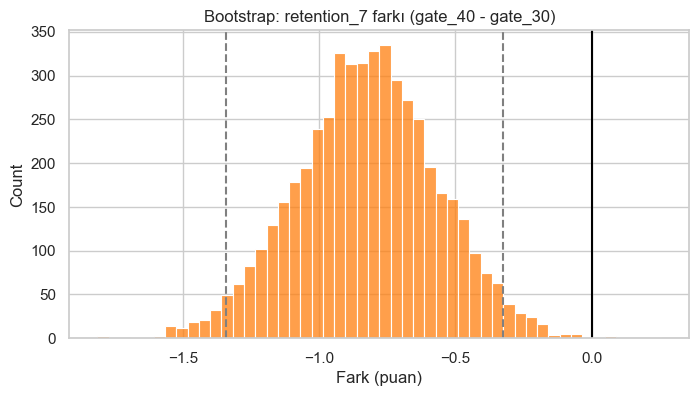

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(boot["retention_7"], bins=50, color="tab:orange")
plt.axvline(0, color="black")
plt.axvline(boot["retention_7"].quantile(0.025), color="gray", linestyle="--")
plt.axvline(boot["retention_7"].quantile(0.975), color="gray", linestyle="--")
plt.title("Bootstrap: retention_7 farkı (gate_40 - gate_30)")
plt.xlabel("Fark (puan)")
plt.savefig("../figures/05_bootstrap.png", dpi=120, bbox_inches="tight")
plt.show()

Bootstrap güven aralıkları z-testi ile neredeyse aynı çıktı (retention_7 için [-1.34, -0.32]). 5.000 tekrarın %99.9'unda gate_40 daha düşük çıktı. İki yöntem aynı sonucu verdiği için sonuca daha çok güvenebilirim.

## 3. Round sayısı: Mann-Whitney U

Round sayısı çok çarpık olduğu için ortalamaları karşılaştıran t-testi yerine sıralamaya dayalı Mann-Whitney U testini kullandım.

In [6]:
print("Medyan gate_30:", a["sum_gamerounds"].median())
print("Medyan gate_40:", b["sum_gamerounds"].median())

u, p_mw = mannwhitneyu(b["sum_gamerounds"], a["sum_gamerounds"])
print(f"Mann-Whitney U p = {p_mw:.4f}")
print(f"P(gate_40 oyuncusu daha çok oynamış) = {u / (len(a) * len(b)):.3f}")

Medyan gate_30: 17.0
Medyan gate_40: 16.0
Mann-Whitney U p = 0.0509
P(gate_40 oyuncusu daha çok oynamış) = 0.496


p = 0.051, anlamlı değil. Rastgele seçilen bir gate_40 oyuncusunun daha çok oynamış olma olasılığı 0.496, yani neredeyse %50. Kapının yeri oyuncuların ne kadar oynadığını değiştirmemiş, sadece geri dönüp dönmediklerini etkilemiş.

## 4. Çoklu test kontrolü

3 test yaptığım için şans eseri anlamlı sonuç bulma ihtimali artıyor. retention_7'yi baştan ana metrik olarak seçtiğim için düzeltme şart değil, yine de Holm düzeltmesiyle kontrol ettim:

In [7]:
p_values = [results.loc[0, "p"], results.loc[1, "p"], p_mw]
reject, p_holm, _, _ = multipletests(p_values, alpha=0.05, method="holm")
pd.DataFrame({"test": ["retention_7", "retention_1", "sum_gamerounds"],
              "p": p_values, "p_holm": p_holm, "anlamli": reject}).round(4)

,test,p,p_holm,anlamli
0,retention_7,0.0016,0.0048,True
1,retention_1,0.0739,0.1018,False
2,sum_gamerounds,0.0509,0.1018,False


retention_7 düzeltmeden sonra da anlamlı (p = 0.005).

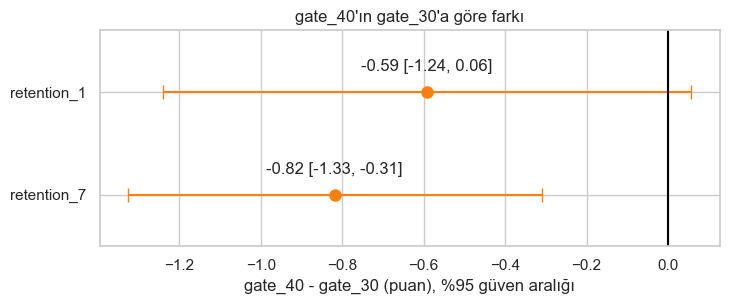

In [8]:
res = results.set_index("metrik")
plt.figure(figsize=(8, 2.8))
for i, col in enumerate(["retention_7", "retention_1"]):
    d, low, high = res.loc[col, ["fark_puan", "ci_alt", "ci_ust"]]
    plt.errorbar(d, i, xerr=[[d - low], [high - d]], fmt="o", color="tab:orange", capsize=5, markersize=8)
    plt.text(d, i + 0.2, f"{d:.2f} [{low:.2f}, {high:.2f}]", ha="center")
plt.axvline(0, color="black")
plt.yticks([0, 1], ["retention_7", "retention_1"])
plt.ylim(-0.5, 1.6)
plt.xlabel("gate_40 - gate_30 (puan), %95 güven aralığı")
plt.title("gate_40'ın gate_30'a göre farkı")
plt.savefig("../figures/06_fark_ci.png", dpi=120, bbox_inches="tight")
plt.show()

## Özet
- **retention_7:** -0.82 puan (göreli -%4.3), %95 GA [-1.33, -0.31], p = 0.0016 → anlamlı. Bootstrap ve Holm düzeltmesi de aynı sonucu veriyor.
- **retention_1:** -0.59 puan, %95 GA [-1.24, 0.06], p = 0.074 → anlamlı değil.
- **Round sayısı:** medyan 17'ye 16, p = 0.051 → pratikte fark yok.
- **Sınırlamalar:** gruplar arası dengesizlik (SRM), level verisi yok, gelir verisi yok.